# 02. Exploratory Analysis

This notebook looks at asking-price distributions and how age relates to two measures of mileage: total recorded mileage and estimated mileage per year.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from features import load_raw, clean, pct_effect, PROCESSED_DIR, ROOT
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)

In [2]:
df = pd.read_csv(PROCESSED_DIR / "cars_clean.csv")
sample = df.sample(5000, random_state=0)  # a sample keeps the scatter plots readable

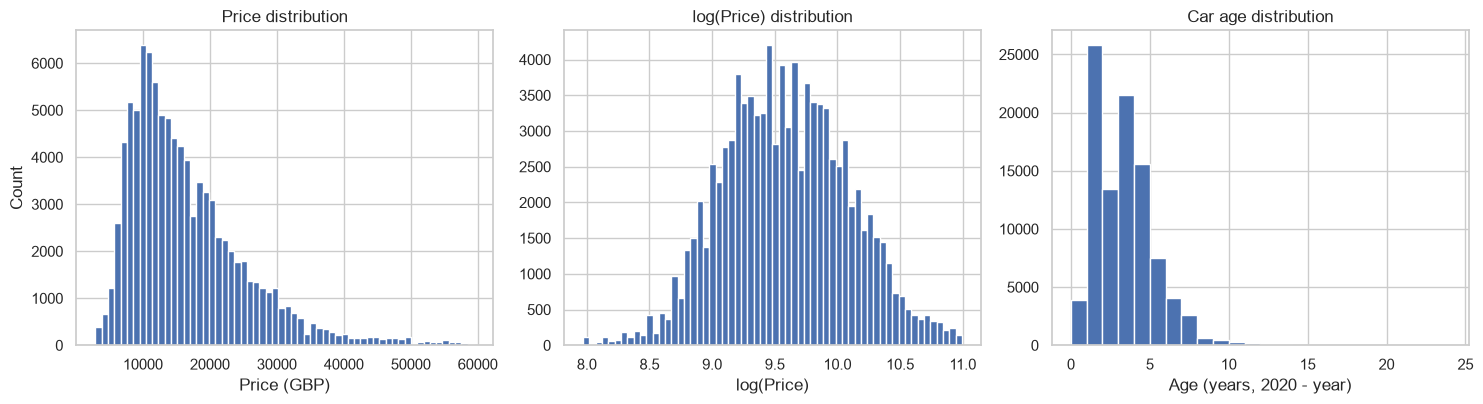

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].hist(df["price"], bins=60, color="#4C72B0")
axes[0].set(title="Price distribution", xlabel="Price (GBP)", ylabel="Count")
axes[1].hist(df["log_price"], bins=60, color="#4C72B0")
axes[1].set(title="log(Price) distribution", xlabel="log(Price)")
axes[2].hist(df["age"], bins=range(0, 25), color="#4C72B0")
axes[2].set(title="Car age distribution", xlabel="Age (years, 2020 - year)")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_distributions.png", dpi=150); plt.show()

Price has a long right tail, so the models use its logarithm.

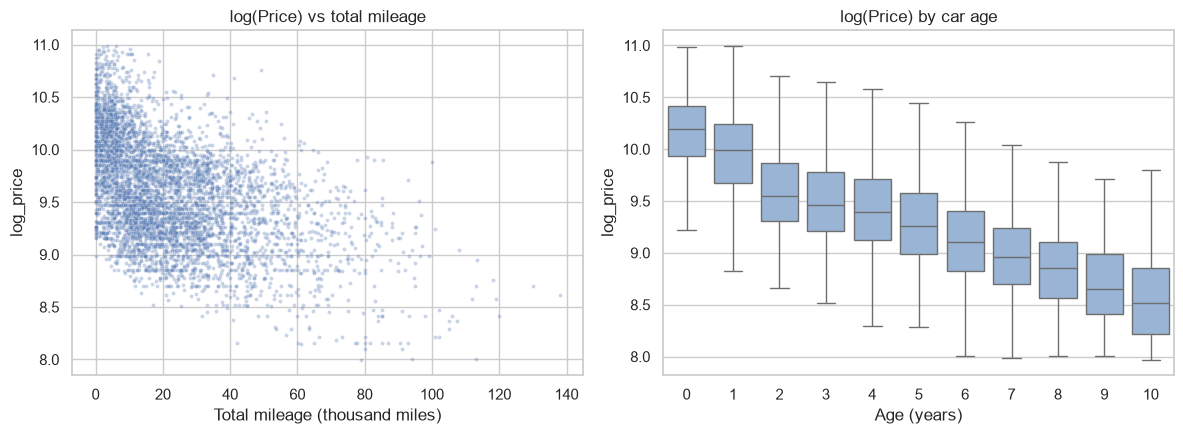

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=sample, x="mileage_k", y="log_price", s=8, alpha=.3, ax=axes[0])
axes[0].set(title="log(Price) vs total mileage", xlabel="Total mileage (thousand miles)")
sns.boxplot(data=df[df.age <= 10], x="age", y="log_price", color="#8fb3de", fliersize=0, ax=axes[1])
axes[1].set(title="log(Price) by car age", xlabel="Age (years)")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_price_vs_mileage_age.png", dpi=150); plt.show()

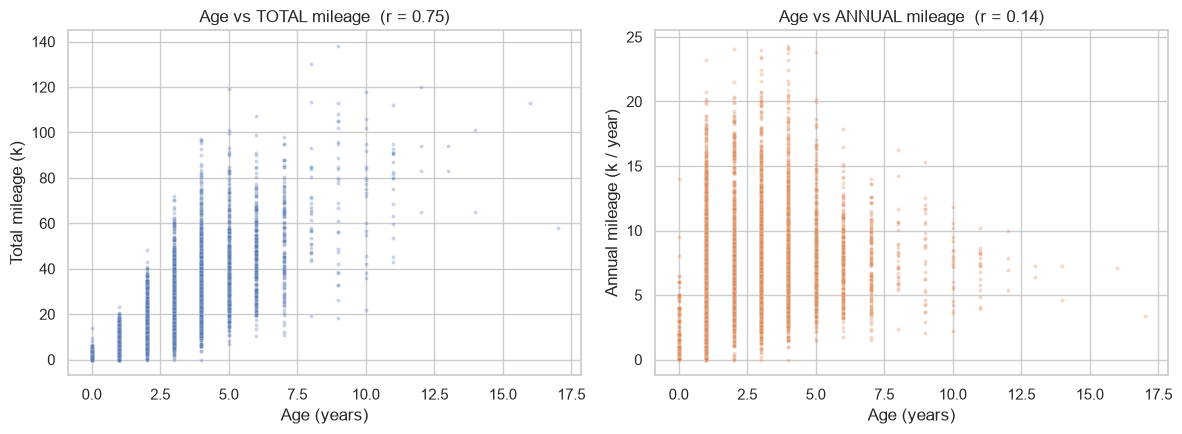

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=sample, x="age", y="mileage_k", s=8, alpha=.3, ax=axes[0])
axes[0].set(title=f"Age vs TOTAL mileage  (r = {df.age.corr(df.mileage):.2f})",
            xlabel="Age (years)", ylabel="Total mileage (k)")
sns.scatterplot(data=sample, x="age", y="annual_mileage_k", s=8, alpha=.3, ax=axes[1], color="#DD8452")
axes[1].set(title=f"Age vs ANNUAL mileage  (r = {df.age.corr(df.annual_mileage):.2f})",
            xlabel="Age (years)", ylabel="Annual mileage (k / year)")
plt.tight_layout(); plt.savefig(FIG_DIR / "03_age_vs_mileage.png", dpi=150); plt.show()

In [6]:
df[["log_price", "age", "mileage", "annual_mileage"]].corr()

,log_price,age,mileage,annual_mileage
log_price,1.000,-0.601,-0.485,-0.167
age,-0.601,1.000,0.752,0.141
mileage,-0.485,0.752,1.000,0.638
annual_mileage,-0.167,0.141,0.638,1.000


## What the correlations show

- Age and total mileage have a correlation of about 0.75. Older cars in the sample have typically accumulated more miles.
- Estimated annual mileage divides total mileage by vehicle age, with a minimum denominator of one year. Its correlation with age is about 0.14.
- The regression notebook compares like-for-like vehicles under each mileage definition. The two definitions hold different quantities constant.